# Modellierung

## Init

In [4]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from sklearn.neural_network import MLPRegressor

# Load the dataset
file_path = '../../data/processed/sickness_table.csv'
df = pd.read_csv(file_path, index_col=0)

# Convert date column to datetime
df['date'] = pd.to_datetime(df['date'])

# Model 1

## Datenselektierung

In [5]:
# Prepare features and target
X = df[['n_duty', 'n_sby', 'month', 'season', 'day_of_week', 'is_holiday', 'is_weekend', 'n_sick']] 

y = df['calls']

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Modellierungvergleiche

In [6]:

# Initialize models
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'Support Vector Machine': SVR(),
    'K-Nearest Neighbors': KNeighborsRegressor(),
    'Neural Network': MLPRegressor(random_state=42, max_iter=1000),
    'Lasso Regression': Lasso(random_state=42),
    'Ridge Regression': Ridge(random_state=42),
    'XGBoost': XGBRegressor(random_state=42)
}

# Train and evaluate each model
results = {}
for model_name, model in models.items():
    start_time = time.time()
    model.fit(X_train, y_train)
    end_time = time.time() 

    training_time = end_time - start_time
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    results[model_name] = {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2, "Training Time" : training_time}
    print(f'{model_name} - MAE: {mae}, MSE: {mse}, RMSE: {rmse}, R2: {r2}, "Training Time (s)" : {training_time}')


Linear Regression - MAE: 844.4126492385662, MSE: 1093068.6499148447, RMSE: 1045.4992347748728, R2: 0.2917026183891873, "Training Time (s)" : 0.0017490386962890625
Decision Tree - MAE: 1061.2857142857142, MSE: 1785570.4285714286, RMSE: 1336.252382063893, R2: -0.15703149965683005, "Training Time (s)" : 0.003192424774169922
Random Forest - MAE: 821.3105553494125, MSE: 1057683.3492077144, RMSE: 1028.4373336318138, R2: 0.31463193379890486, "Training Time (s)" : 0.19144415855407715
Gradient Boosting - MAE: 772.6675382558404, MSE: 902563.3257017874, RMSE: 950.0333287320963, R2: 0.4151481333013015, "Training Time (s)" : 0.059041738510131836
Support Vector Machine - MAE: 1010.6427763456301, MSE: 1580034.105334653, RMSE: 1256.9940752981508, R2: -0.023846050064196378, "Training Time (s)" : 0.030083417892456055
K-Nearest Neighbors - MAE: 821.916883116883, MSE: 1076238.8509090908, RMSE: 1037.4193226025293, R2: 0.30260815718562095, "Training Time (s)" : 0.0012845993041992188
Neural Network - MAE: 88

/usr/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


Models sorted by MAE:


,MAE,MSE,RMSE,R2,Training Time
Gradient Boosting,772.667538,9.025633e+05,950.033329,0.415148,0.059042
Random Forest,821.310555,1.057683e+06,1028.437334,0.314632,0.191444
K-Nearest Neighbors,821.916883,1.076239e+06,1037.419323,0.302608,0.001285
Lasso Regression,844.352199,1.092898e+06,1045.417683,0.291813,0.001817
Ridge Regression,844.391879,1.093036e+06,1045.483792,0.291724,0.001392
Linear Regression,844.412649,1.093069e+06,1045.499235,0.291703,0.001749
Neural Network,886.860897,1.212784e+06,1101.264782,0.214128,2.173227
XGBoost,912.439350,1.291794e+06,1136.571225,0.162931,0.100636
Support Vector Machine,1010.642776,1.580034e+06,1256.994075,-0.023846,0.030083
Decision Tree,1061.285714,1.785570e+06,1336.252382,-0.157031,0.003192


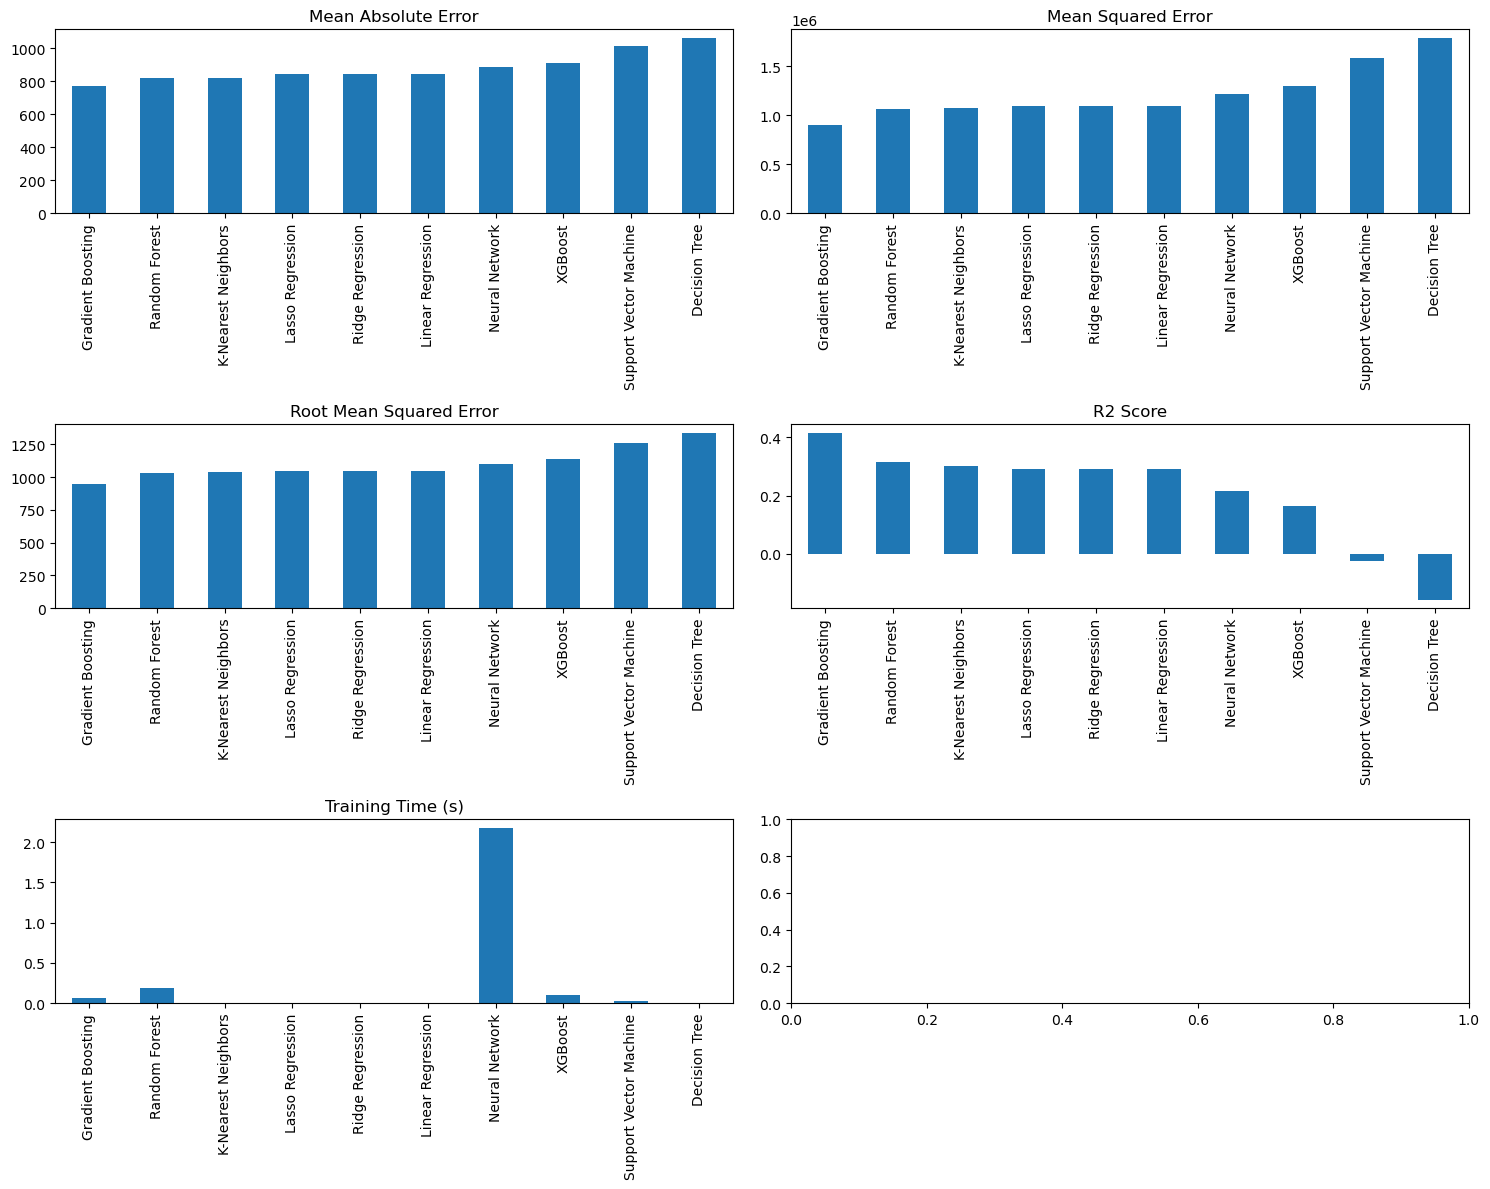

In [7]:
# Convert results to a DataFrame for easier comparison
results_df = pd.DataFrame(results).T

# Sort the models by MAE (you can change the metric to sort by other scores)
results_df_sorted = results_df.sort_values(by='MAE')

print("Models sorted by MAE:")
display(results_df_sorted)

# Visualize the results
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
results_df_sorted['MAE'].plot(kind='bar', ax=axes[0, 0], title='Mean Absolute Error')
results_df_sorted['MSE'].plot(kind='bar', ax=axes[0, 1], title='Mean Squared Error')
results_df_sorted['RMSE'].plot(kind='bar', ax=axes[1, 0], title='Root Mean Squared Error')
results_df_sorted['R2'].plot(kind='bar', ax=axes[1, 1], title='R2 Score')
results_df_sorted['Training Time'].plot(kind='bar', ax=axes[2, 0], title='Training Time (s)')
plt.tight_layout()
plt.show()

In [8]:
# Select the best model based on MAE
best_model_name = results_df_sorted.index[0]
best_model_results = results_df_sorted.loc[best_model_name]

print(f'Best Model: {best_model_name}')
print(best_model_results)

Best Model: Gradient Boosting
MAE                 772.667538
MSE              902563.325702
RMSE                950.033329
R2                    0.415148
Training Time         0.059042
Name: Gradient Boosting, dtype: float64


Final Evaluation of the Best Model (Gradient Boosting):
MAE: 772.6675382558404, MSE: 902563.3257017874, RMSE: 950.0333287320963, R2: 0.4151481333013015


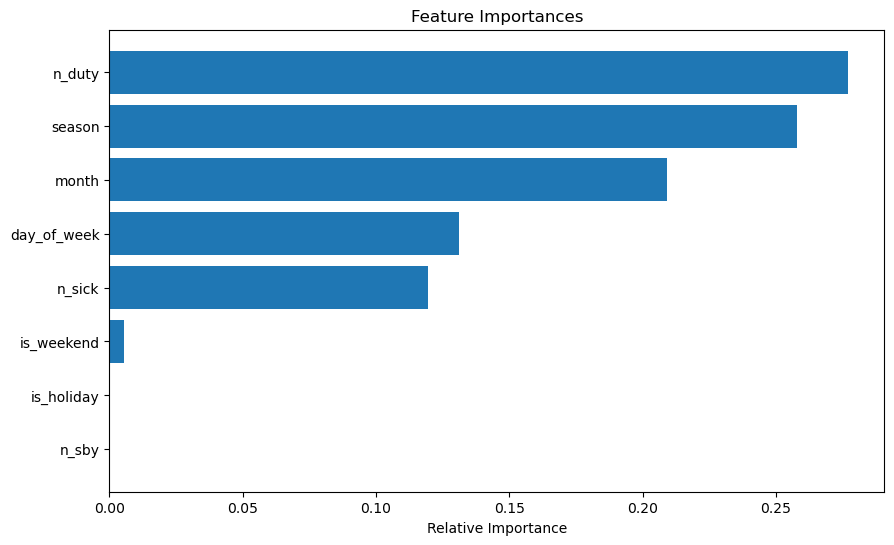

In [9]:
# If further fine-tuning is needed, you can perform hyperparameter tuning on the best model
if best_model_name == 'Random Forest':
    param_grid = {
        'n_estimators': [100, 200],
        'max_depth': [10, 20, None],
        'min_samples_split': [2, 5]
    }
    grid_search = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=5, scoring='neg_mean_absolute_error')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
elif best_model_name == 'Gradient Boosting':
    param_grid = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7]
    }
    grid_search = GridSearchCV(GradientBoostingRegressor(random_state=42), param_grid, cv=5, scoring='neg_mean_absolute_error')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
elif best_model_name == 'XGBoost':
    param_grid = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7]
    }
    grid_search = GridSearchCV(XGBRegressor(random_state=42), param_grid, cv=5, scoring='neg_mean_absolute_error')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
# Add similar tuning for other models if needed

# Train the best model with the entire dataset
best_model.fit(X_train, y_train)
y_pred_best = best_model.predict(X_test)

# Final evaluation of the best model
final_mae = mean_absolute_error(y_test, y_pred_best)
final_mse = mean_squared_error(y_test, y_pred_best)
final_rmse = np.sqrt(final_mse)
final_r2 = r2_score(y_test, y_pred_best)

print(f'Final Evaluation of the Best Model ({best_model_name}):')
print(f'MAE: {final_mae}, MSE: {final_mse}, RMSE: {final_rmse}, R2: {final_r2}')


# Feature Importance for the best model
importances = best_model.feature_importances_
features = X.columns
indices = np.argsort(importances)

plt.figure(figsize=(10, 6))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()


## Modell mit weniger Features (nur die wichtigsten)

In [10]:
best_model_1 = grid_search.best_estimator_

best_model_1.fit(X_train, y_train)

X = df[['n_duty', 'season', 'month', 'day_of_week']]
y = df['calls']

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

best_model_1.fit(X_train, y_train)

GradientBoostingRegressor(random_state=42)

## Prediction Test

In [11]:
predict_data = pd.DataFrame([{
        'n_duty' : 5000, 
        'season' : 1,
        'month' : 5,
        'day_of_week' : 4
    }])


best_model_1.predict(predict_data)

array([9054.15804644])

## Export model

In [12]:
import joblib

# Modell speichern
joblib.dump(best_model_1, '../../app/models/calls_model.pkl')

['../../app/models/calls_model.pkl']

# Model 2

## Datenselektierung

In [34]:
# Prepare features and target
X = df[['calls', 'n_duty', 'month', 'season', 'day_of_week', 'call_stress', 'n_sick']] #dafted and sby_need werden zusammen mit Zielvariable ausgelassen

y = df['sby_need']

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Modellierungvergleiche

In [35]:

# Initialize models
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'Support Vector Machine': SVR(),
    'K-Nearest Neighbors': KNeighborsRegressor(),
    'Neural Network': MLPRegressor(random_state=42, max_iter=1000),
    'Lasso Regression': Lasso(random_state=42),
    'Ridge Regression': Ridge(random_state=42),
    'XGBoost': XGBRegressor(random_state=42)
}

# Train and evaluate each model
results = {}
for model_name, model in models.items():
    start_time = time.time()
    model.fit(X_train, y_train)
    end_time = time.time() 

    training_time = end_time - start_time
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    results[model_name] = {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2, "Training Time" : training_time}
    print(f'{model_name} - MAE: {mae}, MSE: {mse}, RMSE: {rmse}, R2: {r2}, "Training Time (s)" : {training_time}')


Linear Regression - MAE: 6.097881436071569, MSE: 73.57514283667189, RMSE: 8.577595399450354, R2: 0.9805693440414983, "Training Time (s)" : 0.0024852752685546875
Decision Tree - MAE: 3.16017316017316, MSE: 130.42424242424244, RMSE: 11.420343358421515, R2: 0.9655559135125382, "Training Time (s)" : 0.0041904449462890625
Random Forest - MAE: 2.9393073593073593, MSE: 66.5965168831169, RMSE: 8.160668899245755, R2: 0.9824123480064054, "Training Time (s)" : 0.17440557479858398
Gradient Boosting - MAE: 3.414820155878098, MSE: 57.62546378071385, RMSE: 7.591143772891793, R2: 0.9847815373779463, "Training Time (s)" : 0.10184478759765625
Support Vector Machine - MAE: 23.92037203003135, MSE: 3924.5247655663684, RMSE: 62.646027532209644, R2: -0.036438226013631114, "Training Time (s)" : 0.024816513061523438
K-Nearest Neighbors - MAE: 3.0069264069264063, MSE: 76.14805194805193, RMSE: 8.7262851172794, R2: 0.9798898576031682, "Training Time (s)" : 0.0010838508605957031
Neural Network - MAE: 1.83269333227

Models sorted by MAE:


,MAE,MSE,RMSE,R2,Training Time
Neural Network,1.832693,8.504776,2.916295,0.997754,1.014486
XGBoost,2.140893,45.945702,6.778326,0.987866,0.039504
Random Forest,2.939307,66.596517,8.160669,0.982412,0.174406
K-Nearest Neighbors,3.006926,76.148052,8.726285,0.979890,0.001084
Decision Tree,3.160173,130.424242,11.420343,0.965556,0.004190
Gradient Boosting,3.414820,57.625464,7.591144,0.984782,0.101845
Linear Regression,6.097881,73.575143,8.577595,0.980569,0.002485
Ridge Regression,6.363356,75.979564,8.716626,0.979934,0.001018
Lasso Regression,7.590341,99.417457,9.970830,0.973745,0.003901
Support Vector Machine,23.920372,3924.524766,62.646028,-0.036438,0.024817


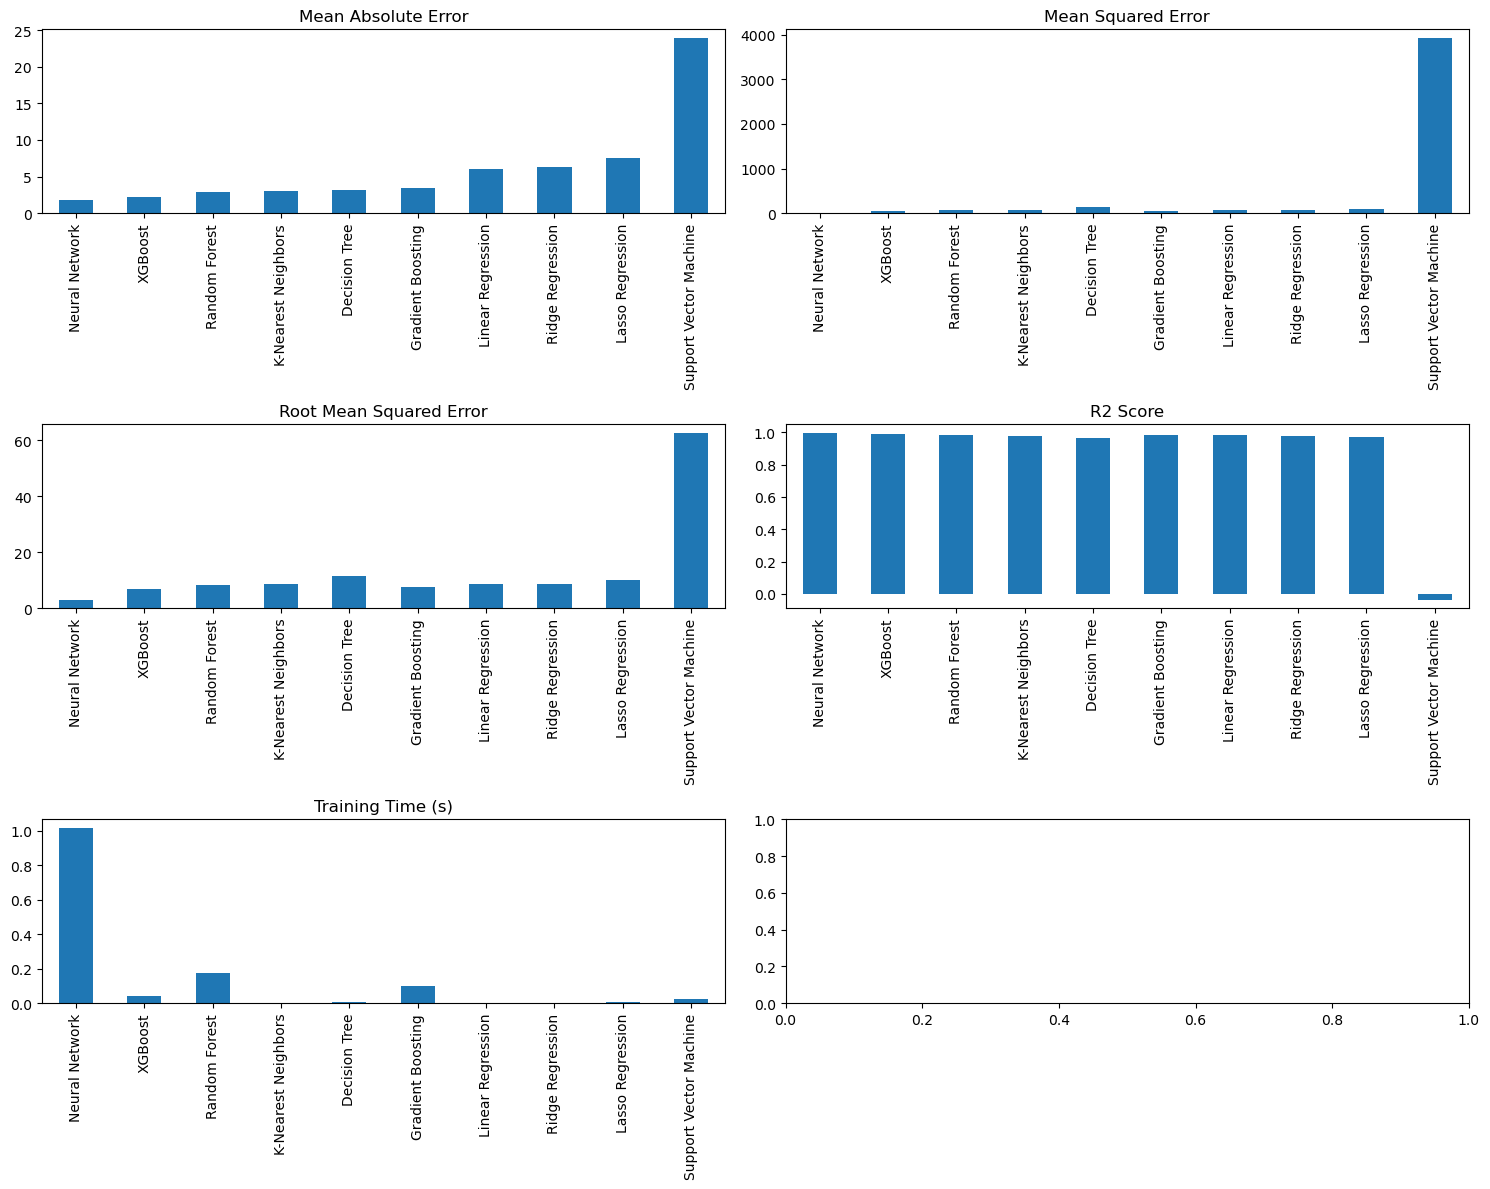

In [36]:
# Convert results to a DataFrame for easier comparison
results_df = pd.DataFrame(results).T

# Sort the models by MAE (you can change the metric to sort by other scores)
results_df_sorted = results_df.sort_values(by='MAE')

print("Models sorted by MAE:")
display(results_df_sorted)

# Visualize the results
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
results_df_sorted['MAE'].plot(kind='bar', ax=axes[0, 0], title='Mean Absolute Error')
results_df_sorted['MSE'].plot(kind='bar', ax=axes[0, 1], title='Mean Squared Error')
results_df_sorted['RMSE'].plot(kind='bar', ax=axes[1, 0], title='Root Mean Squared Error')
results_df_sorted['R2'].plot(kind='bar', ax=axes[1, 1], title='R2 Score')
results_df_sorted['Training Time'].plot(kind='bar', ax=axes[2, 0], title='Training Time (s)')
plt.tight_layout()
plt.show()

In [37]:
# Select the best model based on MAE
best_model_name = results_df_sorted.index[0]
best_model_results = results_df_sorted.loc[best_model_name]

print(f'Best Model: {best_model_name}')
print(best_model_results)

Best Model: Neural Network
MAE              1.832693
MSE              8.504776
RMSE             2.916295
R2               0.997754
Training Time    1.014486
Name: Neural Network, dtype: float64


Final Evaluation of the Best Model (Neural Network):
MAE: 2.336859013061785, MSE: 25.03194582350157, RMSE: 5.003193562466034, R2: 0.9933892465781815


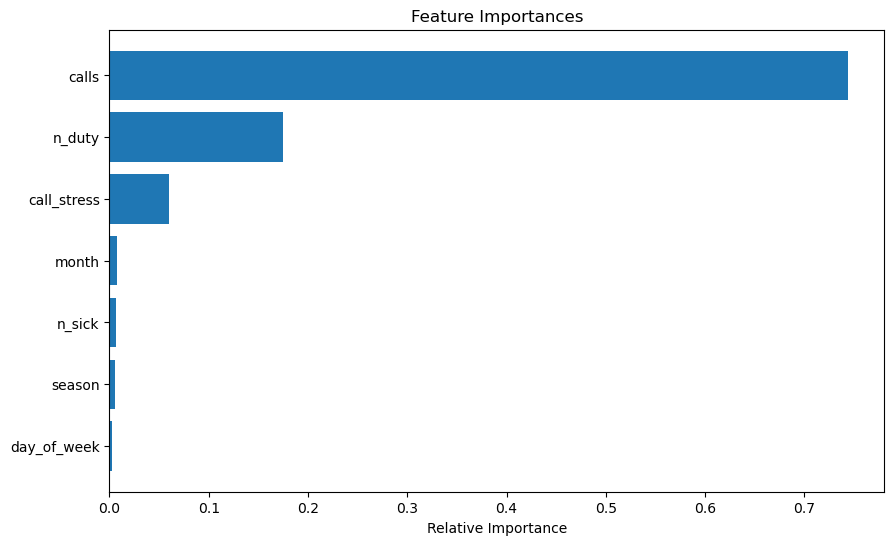

In [38]:
# If further fine-tuning is needed, you can perform hyperparameter tuning on the best model
if best_model_name == 'Random Forest':
    param_grid = {
        'n_estimators': [100, 200],
        'max_depth': [10, 20, None],
        'min_samples_split': [2, 5]
    }
    grid_search = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=5, scoring='neg_mean_absolute_error')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
elif best_model_name == 'Gradient Boosting':
    param_grid = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7]
    }
    grid_search = GridSearchCV(GradientBoostingRegressor(random_state=42), param_grid, cv=5, scoring='neg_mean_absolute_error')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
elif best_model_name == 'XGBoost':
    param_grid = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7]
    }
    grid_search = GridSearchCV(XGBRegressor(random_state=42), param_grid, cv=5, scoring='neg_mean_absolute_error')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
# Add similar tuning for other models if needed

# Train the best model with the entire dataset
best_model.fit(X_train, y_train)
y_pred_best = best_model.predict(X_test)

# Final evaluation of the best model
final_mae = mean_absolute_error(y_test, y_pred_best)
final_mse = mean_squared_error(y_test, y_pred_best)
final_rmse = np.sqrt(final_mse)
final_r2 = r2_score(y_test, y_pred_best)

print(f'Final Evaluation of the Best Model ({best_model_name}):')
print(f'MAE: {final_mae}, MSE: {final_mse}, RMSE: {final_rmse}, R2: {final_r2}')


# Feature Importance for the best model
importances = best_model.feature_importances_
features = X.columns
indices = np.argsort(importances)

plt.figure(figsize=(10, 6))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()


## Modell mit weniger Features (nur die wichtigsten)

In [40]:
best_model_2 = grid_search.best_estimator_

best_model_2.fit(X_train, y_train)

X = df[['calls', 'n_duty', 'month', 'day_of_week']]
y = df['sby_need']

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

best_model_2.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.2, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=3, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=200, n_jobs=None,
             num_parallel_tree=None, random_state=42, ...)

## Prediction Test

In [41]:
predict_data = pd.DataFrame([{
        'calls' : 12000,
        'n_duty' : 2000,
        'month' : 4,
        "day_of_week" : 4

    }])


best_model_2.predict(predict_data)

array([591.02216], dtype=float32)

In [42]:
import joblib

# Modell speichern
joblib.dump(best_model_2, '../../app/models/sby_percent.pkl')

['../../app/models/sby_percent.pkl']

# Full test

In [43]:
model_1 = joblib.load('../../app/models/calls_model.pkl')
model_2 = joblib.load('../../app/models/sby_percent.pkl')

In [58]:
# Prepare features and target
X = df[['n_duty', 'n_sby', 'month', 'season', 'day_of_week', 'is_holiday', 'is_weekend', 'calls']] 

y = df[['calls', 'sby_need']]

# Split data into training and test sets
_, X_test, _, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [59]:
X_test

,n_duty,n_sby,month,season,day_of_week,is_holiday,is_weekend,calls
174,1700,90,9,3,3,False,False,8286.0
754,1900,90,4,1,2,False,False,9174.0
584,1800,90,11,3,0,False,False,7494.0
240,1700,90,11,3,6,False,True,5526.0
715,1900,90,3,1,5,False,True,7932.0
...,...,...,...,...,...,...,...,...
359,1800,90,3,1,6,False,True,6756.0
63,1700,90,6,2,4,False,False,8922.0
388,1800,90,4,1,0,False,False,8184.0
1068,1900,90,3,1,1,False,False,9312.0


In [60]:
y_test

,calls,sby_need
174,8286.0,35.0
754,9174.0,0.0
584,7494.0,0.0
240,5526.0,0.0
715,7932.0,0.0
...,...,...
359,6756.0,0.0
63,8922.0,154.0
388,8184.0,0.0
1068,9312.0,25.0


In [61]:
X_test["calls"] = model_1.predict(X_test[['n_duty', 'season', 'month', 'day_of_week']])

In [62]:
X_test

,n_duty,n_sby,month,season,day_of_week,is_holiday,is_weekend,calls
174,1700,90,9,3,3,False,False,7809.778381
754,1900,90,4,1,2,False,False,9460.754232
584,1800,90,11,3,0,False,False,7692.080373
240,1700,90,11,3,6,False,True,6035.428267
715,1900,90,3,1,5,False,True,8651.636445
...,...,...,...,...,...,...,...,...
359,1800,90,3,1,6,False,True,6587.451032
63,1700,90,6,2,4,False,False,7828.840258
388,1800,90,4,1,0,False,False,8597.652857
1068,1900,90,3,1,1,False,False,8812.034985


In [63]:
X_test["sby_need"] = model_2.predict(X_test[['calls', 'n_duty', 'month', 'day_of_week']])

In [64]:
X_test

,n_duty,n_sby,month,season,day_of_week,is_holiday,is_weekend,calls,sby_need
174,1700,90,9,3,3,False,False,7809.778381,0.521348
754,1900,90,4,1,2,False,False,9460.754232,65.687408
584,1800,90,11,3,0,False,False,7692.080373,-0.110618
240,1700,90,11,3,6,False,True,6035.428267,-0.009952
715,1900,90,3,1,5,False,True,8651.636445,-4.340902
...,...,...,...,...,...,...,...,...,...
359,1800,90,3,1,6,False,True,6587.451032,0.085994
63,1700,90,6,2,4,False,False,7828.840258,-0.158384
388,1800,90,4,1,0,False,False,8597.652857,2.586830
1068,1900,90,3,1,1,False,False,8812.034985,-0.654961


In [65]:
y_test = y_test.rename(columns={"calls" : "orig_calls", "sby_need" : "sby_need_orig"})

In [68]:
result = pd.merge(X_test, y_test, left_index=True, right_index=True)

result["sby_need_diff"] = result.apply(lambda row: (row.sby_need_orig  - row.sby_need), axis=1)

In [69]:
result

,n_duty,n_sby,month,season,day_of_week,is_holiday,is_weekend,calls,sby_need,orig_calls,sby_need_orig,sby_need_diff
174,1700,90,9,3,3,False,False,7809.778381,0.521348,8286.0,35.0,34.478652
754,1900,90,4,1,2,False,False,9460.754232,65.687408,9174.0,0.0,-65.687408
584,1800,90,11,3,0,False,False,7692.080373,-0.110618,7494.0,0.0,0.110618
240,1700,90,11,3,6,False,True,6035.428267,-0.009952,5526.0,0.0,0.009952
715,1900,90,3,1,5,False,True,8651.636445,-4.340902,7932.0,0.0,4.340902
...,...,...,...,...,...,...,...,...,...,...,...,...
359,1800,90,3,1,6,False,True,6587.451032,0.085994,6756.0,0.0,-0.085994
63,1700,90,6,2,4,False,False,7828.840258,-0.158384,8922.0,154.0,154.158384
388,1800,90,4,1,0,False,False,8597.652857,2.586830,8184.0,0.0,-2.586830
1068,1900,90,3,1,1,False,False,8812.034985,-0.654961,9312.0,25.0,25.654961


In [57]:
# Problem: Schlechte Prognose der Calls sorgt für schlechte Prognose bei sby_used_percent

In [33]:
result.describe()

,n_duty,n_sby,month,season,day_of_week,calls,sby_used_percent,orig_calls,orig_sby_used_percent
count,231.000000,231.0,231.000000,231.000000,231.000000,231.000000,231.000000,231.000000,231.000000
mean,1818.614719,90.0,6.428571,1.510823,3.264069,7914.711107,7.936984,7810.727273,27.287157
std,79.398738,0.0,3.337906,1.102809,2.046090,921.695110,24.378361,1244.967382,68.520636
min,1700.000000,90.0,1.000000,0.000000,0.000000,5523.489565,-6.248433,4074.000000,0.000000
25%,1800.000000,90.0,4.000000,1.000000,2.000000,7198.782179,-0.181769,6882.000000,0.000000
50%,1800.000000,90.0,6.000000,1.000000,3.000000,7988.946489,0.124420,7812.000000,0.000000
75%,1900.000000,90.0,9.000000,2.500000,5.000000,8597.652857,2.873742,8670.000000,0.000000
max,1900.000000,90.0,12.000000,3.000000,6.000000,9614.253753,114.417419,10698.000000,365.555556
